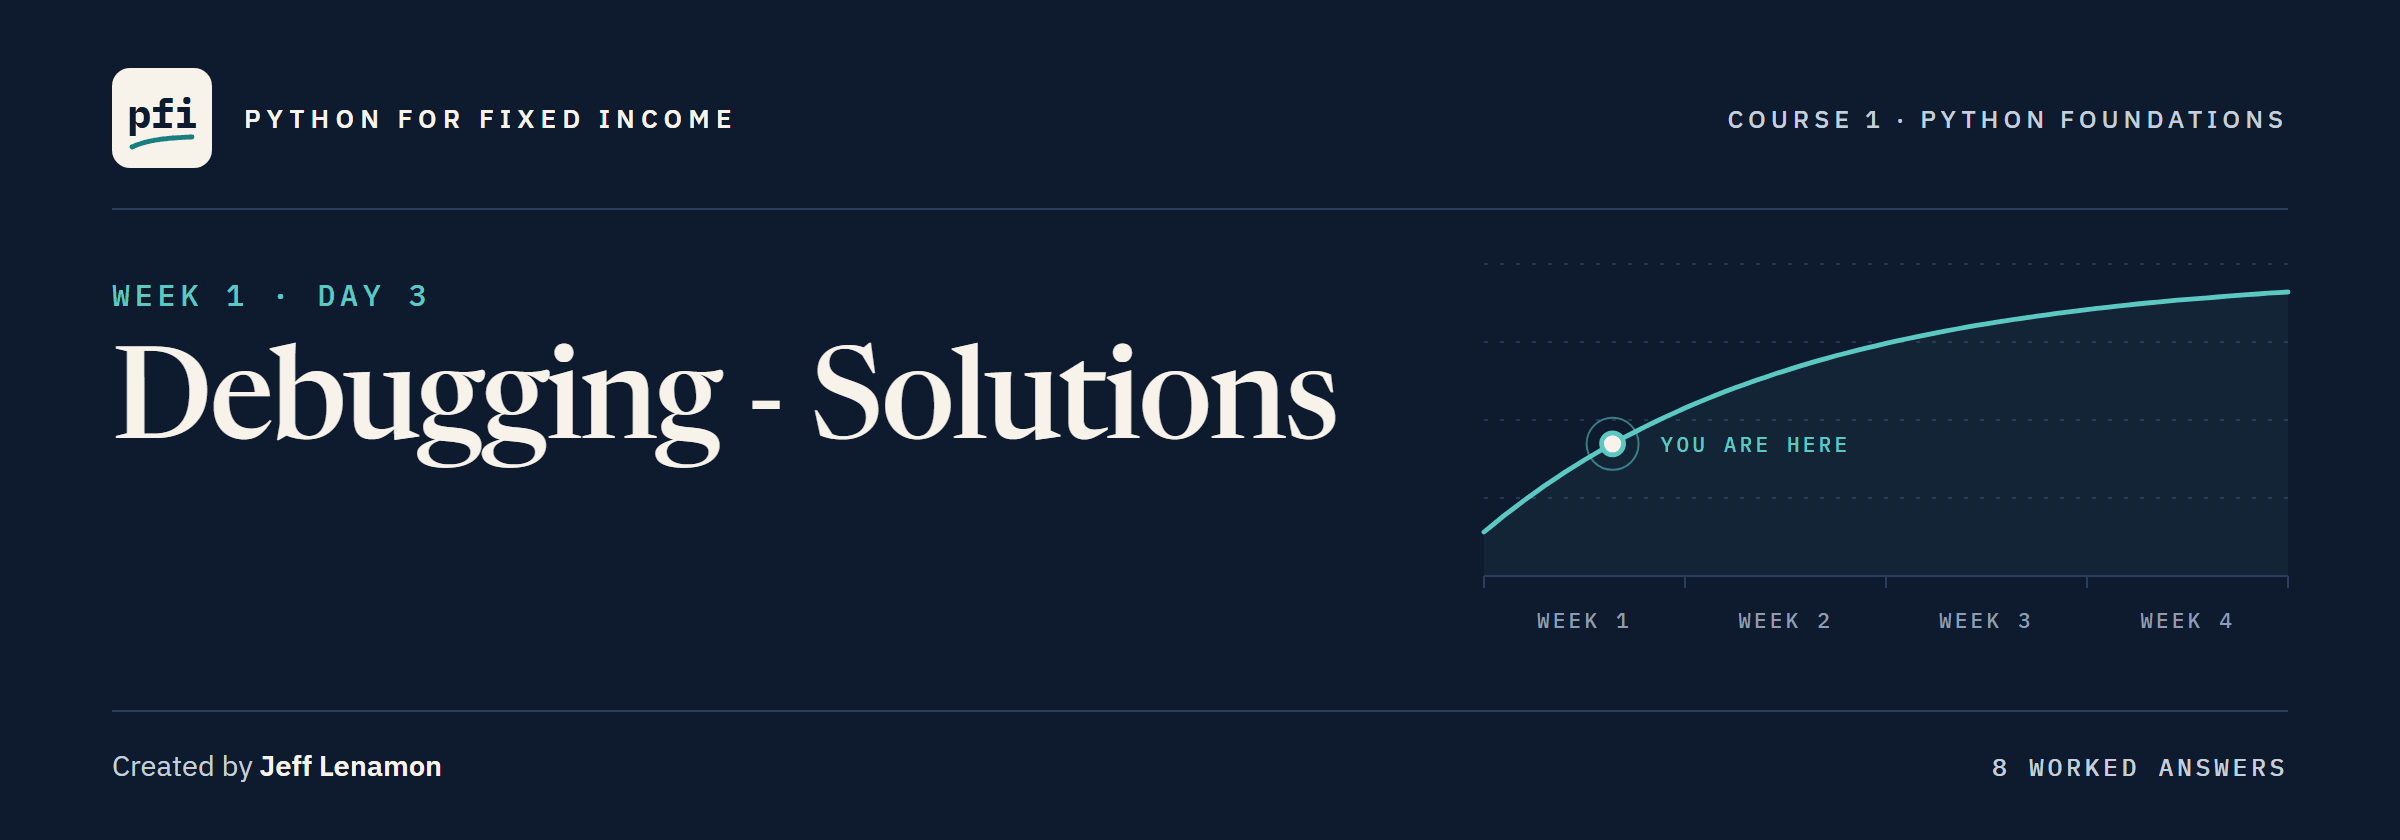

# Debugging - Solutions

Week 1, Day 3. Worked answers to the exercises. Try each one yourself first.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course01_python_foundations/week1/day3/03_debugging_solutions.ipynb)

## Exercises

The analyst also wrote code for a second desk.

<table align="left">
<tr><th align="left">Ticker</th><th align="left">Coupon (%)</th><th align="left">Price</th><th align="left">Rating</th><th align="left">Score</th><th align="left">Face held</th></tr>
<tr><td align="left">TRNW</td><td align="left">4.375</td><td align="left">96.25</td><td align="left">A</td><td align="left">6</td><td align="left">2,000,000</td></tr>
<tr><td align="left">OSMC</td><td align="left">5.00</td><td align="left">100.00</td><td align="left">BBB-</td><td align="left">10</td><td align="left">1,250,000</td></tr>
<tr><td align="left">CLDB</td><td align="left">8.25</td><td align="left">104.50</td><td align="left">B</td><td align="left">15</td><td align="left">500,000</td></tr>
</table>
<br clear="left">

Run the next cell first: it defines `check`, stores the desk's data, and sets each answer to `...`.

In [1]:
def check(label, answer, expected):
    """Compare an exercise answer to the expected value and print the result."""
    if answer is ... or answer is None:
        print(label + ': not attempted yet')
    elif answer == expected:
        print(label + ': correct')
    else:
        print(label + ': not yet. You have', answer)


# the second desk's data
ticker_list = ['TRNW', 'OSMC', 'CLDB']
coupon_list = [4.375, 5.0, 8.25]
price_list = [96.25, 100.0, 104.5]
face_list = [2000000, 1250000, 500000]

# each answer starts as the placeholder ..., which check() reads as not attempted
ex1_total_face = ...
ex2_current_yield = ...
ex3_tickers = ...
ex4_average_price = ...
ex5_total_coupon = ...
ex5_bad_count = ...
ex6_average = ...
ex6_stops = ...
ex7_what_if = ...
ex8_ig_count = ...

### Exercise 1

Q. Fix this code so that **ex1_total_face** holds the total face held.

In [2]:
ex1_total_face = 0
# the colon at the end of the for line was missing
for face in face_list:
    ex1_total_face = ex1_total_face + face

print('The total face held is', ex1_total_face)

The total face held is 3750000


It was a `SyntaxError`: the `for` line had no colon, so Python could not read the cell and none of it ran.

In [3]:
check('Exercise 1', ex1_total_face, 3750000)

Exercise 1: correct


### Exercise 2

Q. Fix this code so that **ex2_current_yield** holds TRNW's current yield, rounded to 2 decimals.

In [4]:
bond = {'Ticker': 'TRNW', 'Coupon': 4.375, 'Price': 96.25}

# the keys are 'Coupon' and 'Price', with capital letters
ex2_current_yield = round(bond['Coupon'] / bond['Price'] * 100, 2)
print('The current yield of TRNW is', ex2_current_yield)

The current yield of TRNW is 4.55


It was a `KeyError`: the code asked for 'coupon' and 'price', and the keys are stored as 'Coupon' and 'Price'.
Fixing the first key reveals the second, so there were two places to change.

In [5]:
check('Exercise 2', ex2_current_yield, 4.55)

Exercise 2: correct


### Exercise 3

Q. Fix this code so that **ex3_tickers** lists all three tickers, taken by position.

In [6]:
ex3_tickers = []
# three items sit at positions 0, 1, and 2, so the range is range(3)
for i in range(3):
    ex3_tickers.append(ticker_list[i])

print(ex3_tickers)

['TRNW', 'OSMC', 'CLDB']


It was an `IndexError`: `range(1, 4)` gave 1, 2, and 3, which skipped the first ticker and then asked for position 3, one past the end.

In [7]:
check('Exercise 3', ex3_tickers, ['TRNW', 'OSMC', 'CLDB'])

Exercise 3: correct


### Exercise 4

Q. The prices arrived from a file as text. Fix this code so that **ex4_average_price** holds their simple average.

In [8]:
price_text_list = ['96.25', '100.0', '104.5']

total = 0
for text in price_text_list:
    # convert each price from text to a number before adding it
    total = total + float(text)

ex4_average_price = total / len(price_text_list)
print('The average price is', ex4_average_price)

The average price is 100.25


It was a `TypeError`: the prices were strings, and Python cannot add a string to the number 0.
`float()` converts each one first.

In [9]:
check('Exercise 4', ex4_average_price, 100.25)

Exercise 4: correct


### Exercise 5

Q. One coupon arrived as 'TBD'. Fix this code with `try` and `except`, so that **ex5_total_coupon** adds up the coupons that are numbers and **ex5_bad_count** counts the ones that are not.

In [10]:
coupon_text_list = ['4.375', 'TBD', '8.25']

ex5_total_coupon = 0
ex5_bad_count = 0
for text in coupon_text_list:
    try:
        # add the coupon if the text is a number
        ex5_total_coupon = ex5_total_coupon + float(text)
    except ValueError:
        # count the text that is not a number, and carry on
        ex5_bad_count = ex5_bad_count + 1

print(f'Total of the coupons that are numbers: {ex5_total_coupon}')
print(f'Values that are not numbers: {ex5_bad_count}')

Total of the coupons that are numbers: 12.625
Values that are not numbers: 1


`float('TBD')` raises a `ValueError`; inside `try`, that sends Python to the `except` block, which counts the bad value, and the loop carries on.
The error is named: a bare `except:` would also hide a misspelled name inside the loop.

In [11]:
check('Exercise 5 total', ex5_total_coupon, 12.625)
check('Exercise 5 bad values', ex5_bad_count, 1)

Exercise 5 total: correct
Exercise 5 bad values: correct


### Exercise 6

Q. Write **average_price**: it takes a list of prices and returns their simple average.
If the list is empty it must stop, with `raise ValueError` and the message 'the price list is empty'.

In [12]:
def average_price(prices):
    """Return the simple average of a list of prices. Stop if the list is empty."""
    # an average of nothing has no meaning, so refuse it and say why
    if len(prices) == 0:
        raise ValueError('the price list is empty')
    return sum(prices) / len(prices)

The three prices average 100.25.
Without the check, an empty list would raise a `ZeroDivisionError`, which names the arithmetic; the message names the cause.
A function handed a bad value uses `raise`, as in 3.9; `assert` is for your own totals.

In [13]:
ex6_average = average_price(price_list)

# does the function stop when it is handed an empty list?
if ex6_average is not None:
    try:
        average_price([])
        ex6_stops = False
    except ValueError:
        ex6_stops = True

check('Exercise 6 average', ex6_average, 100.25)
check('Exercise 6 stops on an empty list', ex6_stops, True)

Exercise 6 average: correct
Exercise 6 stops on an empty list: correct


### Exercise 7

Q. This code should leave `price_list` as it is and build **ex7_what_if**, with CLDB marked at 99.5.
It runs with no error; fix it so that both checks pass.

In [14]:
price_list = [96.25, 100.0, 104.5]

# .copy() makes a separate list, so the desk's list is left alone
ex7_what_if = price_list.copy()
ex7_what_if[2] = 99.5

print(f'What-if prices: {ex7_what_if}')
print(f'Desk prices:    {price_list}')

What-if prices: [96.25, 100.0, 99.5]
Desk prices:    [96.25, 100.0, 104.5]


`ex7_what_if = price_list` gave one list two names, so the new mark landed on the desk's list as well; `.copy()` makes a second list.
The first check passes with or without the fix: the check on the list that was meant to stay the same is the one that finds the bug.

In [15]:
check('Exercise 7 what-if list', ex7_what_if, [96.25, 100.0, 99.5])
check('Exercise 7 desk list', price_list, [96.25, 100.0, 104.5])

Exercise 7 what-if list: correct
Exercise 7 desk list: correct


### Exercise 8: AI check

An AI assistant wrote code to count the investment grade bonds, those with a score of 10 or lower; it has one bug.

Q. Count them yourself from the table first. Then run the code. Does it agree?

From the table, TRNW (score 6) and OSMC (score 10) are investment grade, so the answer is 2; the original code printed 1, with no error.
The bug was the comparison `score < 10`, which leaves out a score of exactly 10: BBB-, the lowest investment grade rating.
The test has to be `score <= 10`.
The mistake sits exactly on the boundary, which is where comparison bugs hide: always test the value right at the line.

In [16]:
score_list = [6, 10, 15]

ex8_ig_count = 0
for score in score_list:
    # <= includes a score of exactly 10
    if score <= 10:
        ex8_ig_count = ex8_ig_count + 1

print('Investment grade bonds:', ex8_ig_count)

Investment grade bonds: 2


In [17]:
check('Exercise 8', ex8_ig_count, 2)

Exercise 8: correct


[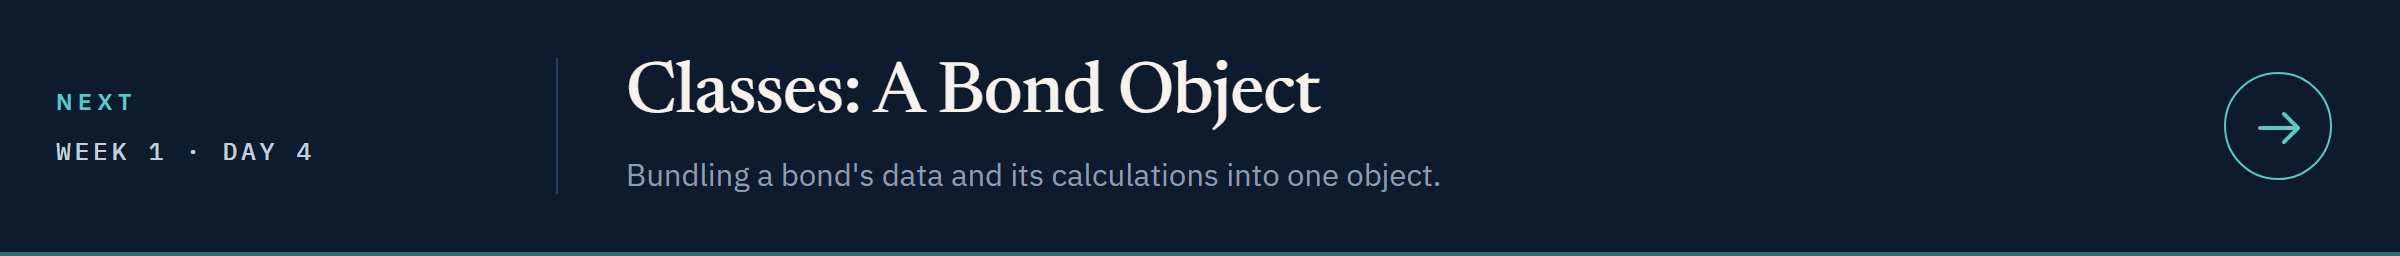](../day4/04_classes_a_bond_object.ipynb)

[Open Day 4 in Colab](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course01_python_foundations/week1/day4/04_classes_a_bond_object.ipynb)